<a href="https://colab.research.google.com/github/MrPraphul/Assessment_Supervised/blob/main/Assessment_supervised_Praphul.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [48]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns




In [49]:

df = pd.read_csv('/content/drive/MyDrive/DSA/Dataset/bank_marketing_assessment_dataset.csv')
df.head()




,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [50]:
df.shape

(600, 14)

In [51]:
df.columns

Index(['customer_age', 'job', 'marital_status', 'education', 'account_balance',
       'housing_loan', 'personal_loan', 'contact_type', 'contact_month',
       'campaign_contacts', 'previous_contacts', 'engagement_score',
       'annual_income_estimate', 'subscribed'],
      dtype='object')

In [52]:
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_age            600 non-null    int64  
 1   job                     600 non-null    object 
 2   marital_status          600 non-null    object 
 3   education               585 non-null    object 
 4   account_balance         588 non-null    float64
 5   housing_loan            600 non-null    object 
 6   personal_loan           600 non-null    object 
 7   contact_type            591 non-null    object 
 8   contact_month           600 non-null    object 
 9   campaign_contacts       600 non-null    int64  
 10  previous_contacts       600 non-null    int64  
 11  engagement_score        600 non-null    int64  
 12  annual_income_estimate  600 non-null    int64  
 13  subscribed              600 non-null    object 
dtypes: float64(1), int64(5), object(8)
memory 

In [54]:
df.isnull().sum()

,0
customer_age,0
job,0
marital_status,0
education,15
account_balance,12
housing_loan,0
personal_loan,0
contact_type,9
contact_month,0
campaign_contacts,0


In [55]:
df.duplicated().sum()

np.int64(0)

In [56]:
df['subscribed'].value_counts()

,count
subscribed,
no,426
yes,174


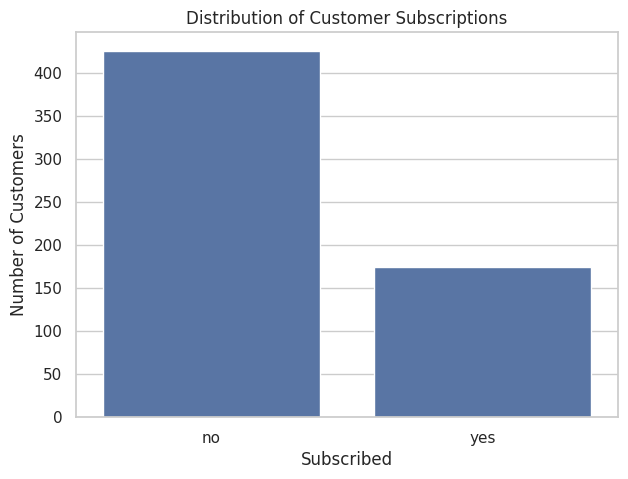

In [57]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='subscribed')

plt.title('Distribution of Customer Subscriptions')
plt.xlabel('Subscribed')
plt.ylabel('Number of Customers')

plt.show()

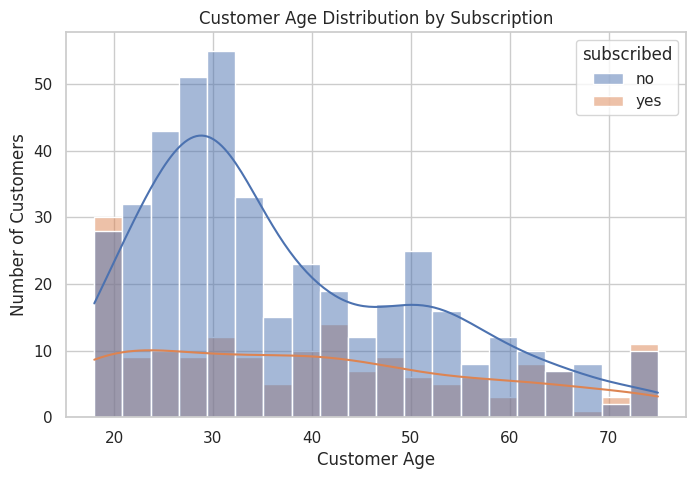

In [58]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='customer_age',
    hue='subscribed',
    bins=20,
    kde=True
)

plt.title('Customer Age Distribution by Subscription')
plt.xlabel('Customer Age')
plt.ylabel('Number of Customers')

plt.show()

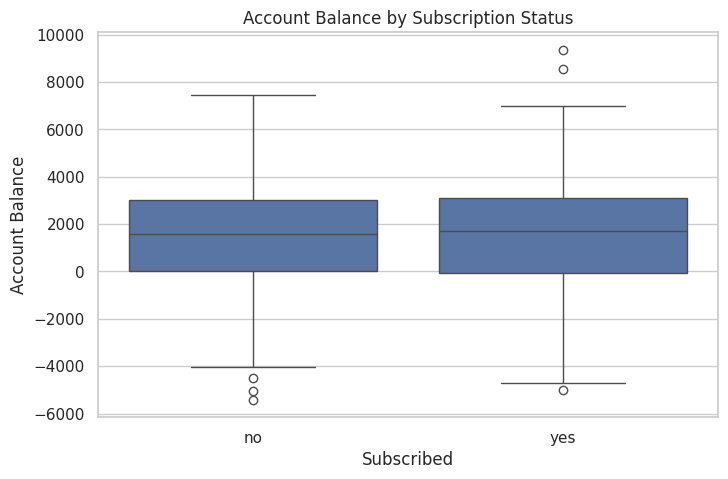

In [59]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='subscribed',
    y='account_balance'
)

plt.title('Account Balance by Subscription Status')
plt.xlabel('Subscribed')
plt.ylabel('Account Balance')

plt.show()

**Account Balance Analysis**

The box plot compares account balances between customers who subscribed and those who did not.

1. Customers who subscribed appear to have a slightly higher median account balance.
2. Both groups show similar distributions with considerable overlap.
3. Several outliers are present in both groups.

Overall, account balance alone does not appear to clearly distinguish subscribers from non-subscribers.


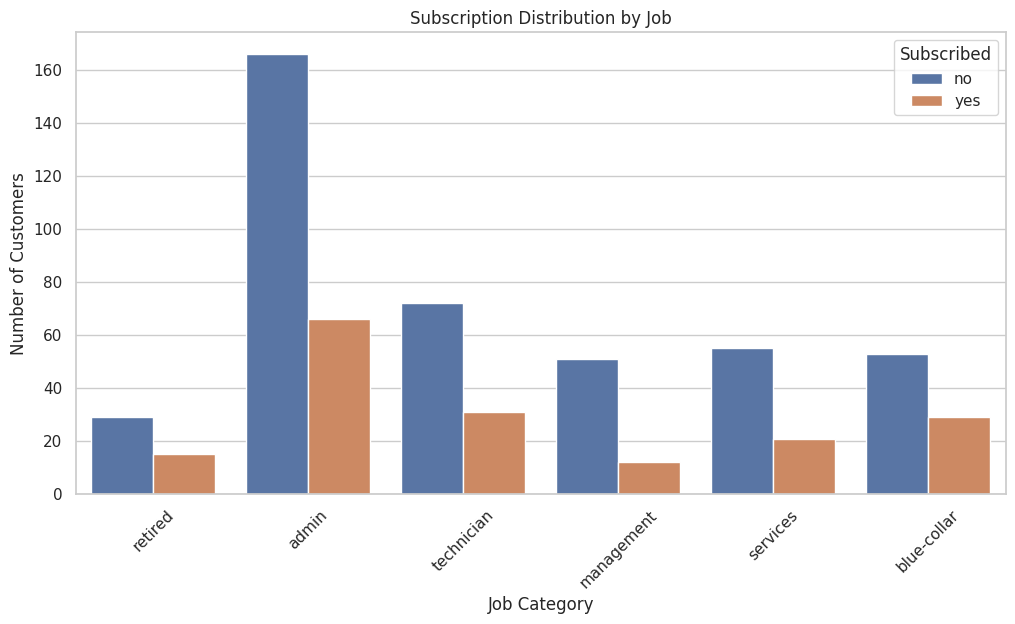

In [60]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='job',
    hue='subscribed'
)

plt.title('Subscription Distribution by Job')
plt.xlabel('Job Category')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

plt.legend(title='Subscribed')

plt.show()

In [61]:
X = df.drop('subscribed', axis=1)

y = df['subscribed']

#**2.Data Preparatin and Feature Engineering**

In [62]:
from sklearn.model_selection import train_test_split

In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [64]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (480, 13)
Testing data: (120, 13)


In [65]:
from sklearn.impute import SimpleImputer
import pandas as pd

# Identify numerical and categorical columns
num_cols = X_train.select_dtypes(include=['number']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

# Handle numerical missing values (using median)
num_imputer = SimpleImputer(strategy='median')
X_train_num_imputed = pd.DataFrame(num_imputer.fit_transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
X_test_num_imputed = pd.DataFrame(num_imputer.transform(X_test[num_cols]), columns=num_cols, index=X_test.index)

# Handle categorical missing values (using mode)
cat_imputer = SimpleImputer(strategy='most_frequent')
X_train_cat_imputed = pd.DataFrame(cat_imputer.fit_transform(X_train[cat_cols]), columns=cat_cols, index=X_train.index)
X_test_cat_imputed = pd.DataFrame(cat_imputer.transform(X_test[cat_cols]), columns=cat_cols, index=X_test.index)

print("Missing values handled successfully.")

Missing values handled successfully.


In [66]:
from sklearn.preprocessing import StandardScaler

# Fit scaler strictly on imputed training numerical data
scaler = StandardScaler()
X_train_num_scaled = pd.DataFrame(scaler.fit_transform(X_train_num_imputed), columns=num_cols, index=X_train.index)
X_test_num_scaled = pd.DataFrame(scaler.transform(X_test_num_imputed), columns=num_cols, index=X_test.index)

print("Numerical features scaled successfully.")

Numerical features scaled successfully.


In [67]:
from sklearn.preprocessing import OneHotEncoder

# Fit One-Hot Encoder strictly on imputed training categorical data
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_cat_encoded_raw = encoder.fit_transform(X_train_cat_imputed)
X_test_cat_encoded_raw = encoder.transform(X_test_cat_imputed)

# Get feature names for mapping back to dataframe
encoded_cols = encoder.get_feature_names_out(cat_cols)
X_train_cat_encoded = pd.DataFrame(X_train_cat_encoded_raw, columns=encoded_cols, index=X_train.index)
X_test_cat_encoded = pd.DataFrame(X_test_cat_encoded_raw, columns=encoded_cols, index=X_test.index)

print("Categorical features encoded successfully.")

Categorical features encoded successfully.


In [68]:
# Combine numerical and categorical datasets together
X_train_final = pd.concat([X_train_num_scaled, X_train_cat_encoded], axis=1)
X_test_final = pd.concat([X_test_num_scaled, X_test_cat_encoded], axis=1)

X_train_preprocessed = X_train_final.values
X_test_preprocessed = X_test_final.values

print(f"Final training shape: {X_train_final.shape}")
print(f"Final test shape: {X_test_final.shape}")

Final training shape: (480, 31)
Final test shape: (120, 31)


In [69]:
# Ensure preprocessing is fitted only on the training data; avoid data leakage
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline

# Group features by type
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

# Create simple pipelines for both feature types
preprocessor = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols),
    (make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore', sparse_output=False)), cat_cols)
)

# Fit on training data and transform both to prevent data leakage
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

print("Preprocessing completed successfully without data leakage.")

Preprocessing completed successfully without data leakage.


#**3.Model Building**

In [70]:
# Importing linear regresssion model
from sklearn.linear_model import LinearRegression

In [71]:
# Initialize and train the Logistic Regression model
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_preprocessed, y_train)

print("Logistic Regression model successfully trained.")

Logistic Regression model successfully trained.


In [72]:
# Importing DT Classifier
from sklearn.tree import DecisionTreeClassifier

In [73]:
# Initialize and train the Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_classifier.fit(X_train_preprocessed, y_train)

print("Decision Tree Classifier successfully trained.")

Decision Tree Classifier successfully trained.


#**4.Model Evaluation And Comparison**

In [74]:
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import accuracy_score, f1_score

In [75]:
print("Logistic Regression:")
print("Accuracy Score:", accuracy_score(y_test, log_reg.predict(X_test_preprocessed)))
print("Precision Score:", precision_score(y_test, log_reg.predict(X_test_preprocessed), pos_label='yes'))
print("Recall Score:", recall_score(y_test, log_reg.predict(X_test_preprocessed), pos_label='yes'))
print("F1 Score:", f1_score(y_test, log_reg.predict(X_test_preprocessed), pos_label='yes'))

Logistic Regression:
Accuracy Score: 0.85
Precision Score: 0.8695652173913043
Recall Score: 0.5714285714285714
F1 Score: 0.6896551724137931


In [76]:
print("Decision Tree Classifier:")
print("Accuracy Score:", accuracy_score(y_test, dt_classifier.predict(X_test_preprocessed)))
print("Precision Score:", precision_score(y_test, dt_classifier.predict(X_test_preprocessed), pos_label='yes'))
print("Recall Score:", recall_score(y_test, dt_classifier.predict(X_test_preprocessed), pos_label='yes'))
print("F1 Score:", f1_score(y_test, dt_classifier.predict(X_test_preprocessed), pos_label='yes'))

Decision Tree Classifier:
Accuracy Score: 0.8666666666666667
Precision Score: 0.8518518518518519
Recall Score: 0.6571428571428571
F1 Score: 0.7419354838709677


In [77]:
from sklearn.metrics import confusion_matrix

In [78]:
print("Logistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, log_reg.predict(X_test_preprocessed)))

Logistic Regression Confusion Matrix:
[[82  3]
 [15 20]]


In [79]:
print("Decision Tree Classifier Confusion Matrix:")
print(confusion_matrix(y_test, dt_classifier.predict(X_test_preprocessed)))

Decision Tree Classifier Confusion Matrix:
[[81  4]
 [12 23]]


#**5.Business Interpretation and prediction**

# 1

/tmp/ipykernel_4991/1239935550.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance_df.head(10), x='Importance', y='Feature', palette='viridis')


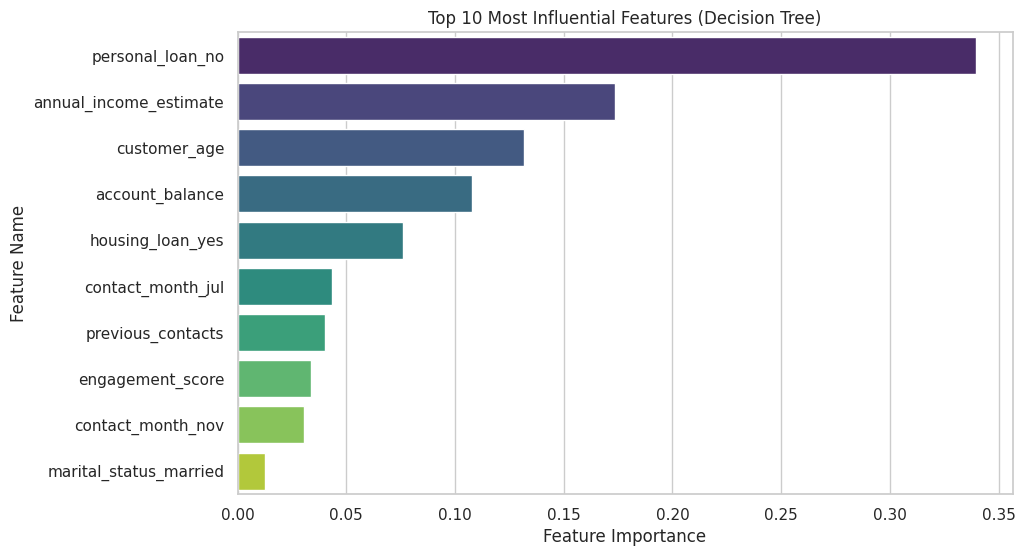

In [80]:
# Extract feature importances
feature_names = num_cols.tolist() + encoded_cols.tolist()
importances = dt_classifier.feature_importances_

# Create a DataFrame for easy viewing
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot top 10 features
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance_df.head(10), x='Importance', y='Feature', palette='viridis')
plt.title('Top 10 Most Influential Features (Decision Tree)')
plt.xlabel('Feature Importance')
plt.ylabel('Feature Name')
plt.show()

#**Limitations of the Interpretation:**

**1. Correlation vs. Causation:** A feature having high importance means it plays a significant role in the tree's decision-making process. However, this does not prove that it has a direct influence on the outcome.

**2. Instability (High Variance):** Decision Trees may produce different results when there are small changes in the training data. This can affect both the tree structure and the importance assigned to each feature.

**3. Bias Toward High Cardinality:** Decision Trees may prefer features with a larger number of distinct values or categories, as they offer more potential ways to divide the data.

#2

In [81]:
# Select 5 sample indices from test data
sample_indices = X_test.index[:5]

# Get preprocessed sample features
samples_preprocessed = X_test_preprocessed[:5]

# Make predictions
predicted_classes = dt_classifier.predict(samples_preprocessed)
predicted_probabilities = dt_classifier.predict_proba(samples_preprocessed)[:, 1]

# Create a display DataFrame
samples_df = X_test.loc[sample_indices].copy()
samples_df['Actual Subscribed'] = y_test.loc[sample_indices].map({0: 'no', 1: 'yes'})
samples_df['Predicted Class'] = ['yes' if p == 1 else 'no' for p in predicted_classes]
samples_df['Probability of Yes'] = predicted_probabilities

display(samples_df[['customer_age', 'job', 'Actual Subscribed', 'Predicted Class', 'Probability of Yes']])

,customer_age,job,Actual Subscribed,Predicted Class,Probability of Yes
269,54,blue-collar,NaN,no,0.000000
70,18,admin,NaN,no,1.000000
376,57,management,NaN,no,0.036199
543,64,services,NaN,no,1.000000
429,23,admin,NaN,no,0.036199


#3

After comparing Logistic Regression and Decision Tree Classifier for predicting term deposit subscriptions, the Decision Tree Classifier was selected as the better-performing model. It achieved a recall of **65.71%**, correctly identifying 23 of the 35 actual subscribers, along with an F1-score of **74.19%**. This makes it more effective at identifying potential customers and reducing missed subscription opportunities. For further improvement, future work could involve using ensemble algorithms such as Random Forest and XGBoost to improve model stability, along with techniques like SMOTE to handle class imbalance in the dataset.